## **EXAMEN SEGUNDO PARCIAL 02/2026 - Inteligencia Artificial I (SIS420)**
### **Ejercicio 1 - Aprendizaje No Supervisado**

**Nombre:** Plaza López Cesar Manuel

**Carrera:** Ingeniería de Sistemas

## **Extracción de parches y preparación del Dataset. -**

In [1]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Soporte para formato HEIC
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass

ruta_origen = "dataset_crudo"
ruta_salida = "dataset_parches_64x64"
archivo_npz = "dataset_quirpinchaca_64x64.npz"
patch_size = (64, 64)
max_parches_por_foto = 20

extensiones = ('.jpg', '.jpeg', '.png', '.bmp', '.heic', '.webp')
os.makedirs(ruta_salida, exist_ok=True)

rutas_fotos = []
for root, _, files in os.walk(ruta_origen):
    for f in files:
        if f.lower().endswith(extensiones):
            rutas_fotos.append(os.path.join(root, f))

print(f"Total de imágenes encontradas en '{ruta_origen}': {len(rutas_fotos)}")

parches = []
total_parches_guardados = 0

for i, path in enumerate(rutas_fotos):
    try:
        with Image.open(path) as img:
            img = img.convert('RGB')
            w, h = img.size
            
            if w < patch_size[0] or h < patch_size[1]:
                continue
            
            stride_x = max(patch_size[0], w // 5)
            stride_y = max(patch_size[1], h // 5)
            
            contador_foto = 0
            for top in range(0, h - patch_size[1] + 1, stride_y):
                for left in range(0, w - patch_size[0] + 1, stride_x):
                    if contador_foto >= max_parches_por_foto:
                        break
                    
                    box = (left, top, left + patch_size[0], top + patch_size[1])
                    patch = img.crop(box)
                    
                    # Guardar parche individual en disco
                    nombre_parche = f"parche_{total_parches_guardados:06d}.jpg"
                    patch.save(os.path.join(ruta_salida, nombre_parche), quality=95)
                    
                    parches.append(np.array(patch, dtype=np.uint8))
                    contador_foto += 1
                    total_parches_guardados += 1
    except Exception:
        continue
        
    if (i + 1) % 50 == 0 or (i + 1) == len(rutas_fotos):
        print(f"Fotos procesadas: {i + 1}/{len(rutas_fotos)} | Parches generados: {total_parches_guardados}")

# Guardar en archivo comprimido
X_raw = np.array(parches, dtype=np.uint8)
np.savez_compressed(archivo_npz, X=X_raw)

print(f"\nDataset listo:")
print(f"Forma de X_raw: {X_raw.shape} (N_muestras, Alto, Ancho, Canales)")

Total de imágenes encontradas en 'dataset_crudo': 566
Fotos procesadas: 50/566 | Parches generados: 1000
Fotos procesadas: 100/566 | Parches generados: 2000
Fotos procesadas: 150/566 | Parches generados: 3000
Fotos procesadas: 200/566 | Parches generados: 4000
Fotos procesadas: 250/566 | Parches generados: 5000
Fotos procesadas: 300/566 | Parches generados: 6000
Fotos procesadas: 350/566 | Parches generados: 7000
Fotos procesadas: 400/566 | Parches generados: 8000
Fotos procesadas: 450/566 | Parches generados: 9000
Fotos procesadas: 500/566 | Parches generados: 10000
Fotos procesadas: 550/566 | Parches generados: 11000
Fotos procesadas: 566/566 | Parches generados: 11320

Dataset listo:
Forma de X_raw: (11320, 64, 64, 3) (N_muestras, Alto, Ancho, Canales)


## **Inspección visual de los parches. -**

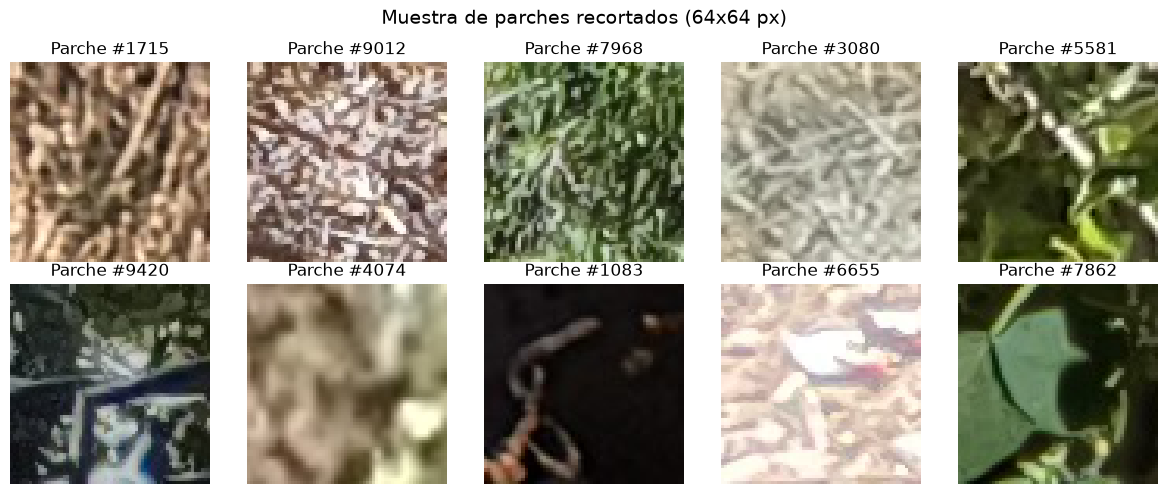

In [2]:
# Mostrar una muestra aleatoria de parches generados
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
indices = np.random.choice(len(X_raw), 10, replace=False)

for ax, idx in zip(axes.ravel(), indices):
    ax.imshow(X_raw[idx])
    ax.axis('off')
    ax.set_title(f"Parche #{idx}")

plt.suptitle("Muestra de parches recortados (64x64 px)", fontsize=14)
plt.tight_layout()
plt.show()

## **Aplanado, normalización y entrenamiento de K-Means. -**
Agruparemos los datos en $K=4$ clusters representativos (Vegetación verde, Maleza seca, Suelo/Piedra y Basura/Plásticos).

In [3]:
from sklearn.cluster import KMeans

# 1. Cargar o preparar datos aplanados (11320 muestras, 12288 características)
X = X_raw.reshape(X_raw.shape[0], -1).astype("float32") / 255.0

print(f"Dimensiones de X para Scikit-Learn: {X.shape}")

# 2. Configurar y entrenar K-Means
k = 4
kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=42)

# y_pred contendrá las etiquetas automáticas (0, 1, 2 o 3) asignadas a cada parche
y_pred = kmeans.fit_predict(X)

print("\nEntrenamiento finalizado.")
print("Primeras 20 etiquetas asignadas automáticamente (y_pred):")
print(y_pred[:20])

# Contar cuántos parches quedaron en cada grupo
for cluster_id in range(k):
    total = np.sum(y_pred == cluster_id)
    print(f"Cluster {cluster_id}: {total} parches ({total/len(y_pred)*100:.1f}%)")

Dimensiones de X para Scikit-Learn: (11320, 12288)

Entrenamiento finalizado.
Primeras 20 etiquetas asignadas automáticamente (y_pred):
[0 3 1 0 1 0 2 0 1 2 3 0 0 0 0 3 3 3 2 0]
Cluster 0: 3674 parches (32.5%)
Cluster 1: 3337 parches (29.5%)
Cluster 2: 1933 parches (17.1%)
Cluster 3: 2376 parches (21.0%)


## **Inspección visual de los Clústers (Asignación de significado).-**

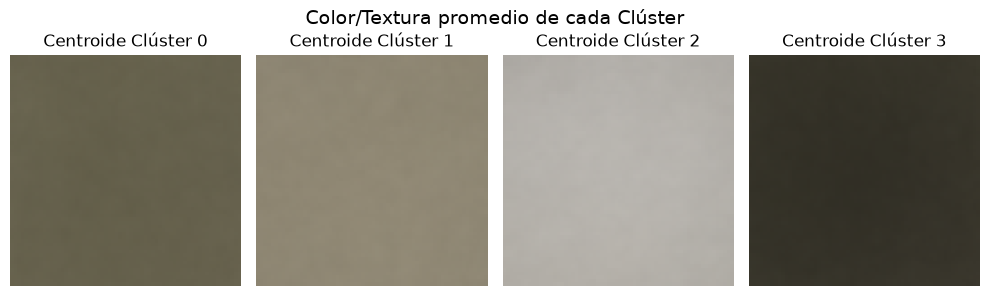

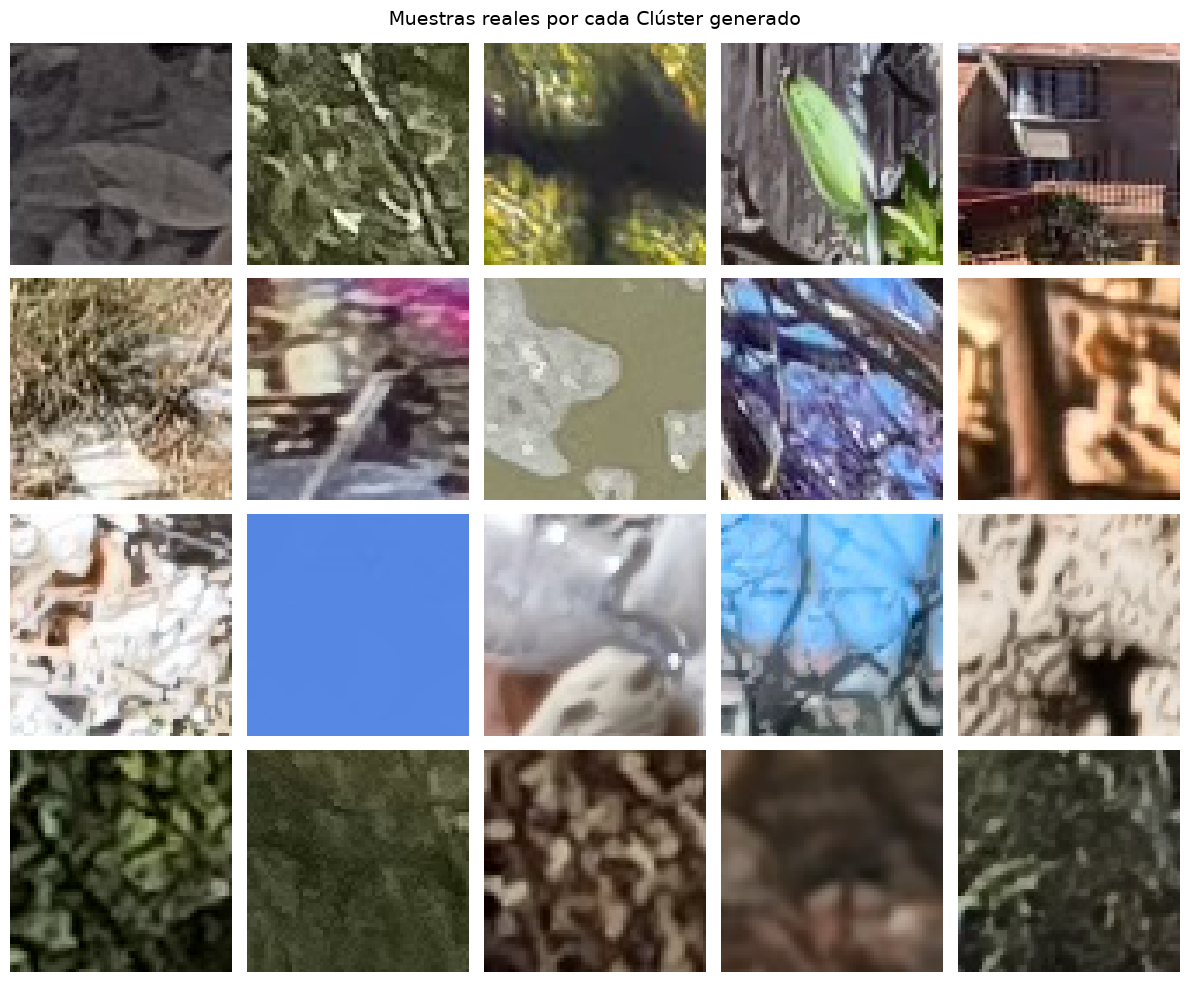

In [4]:
# 1. Visualizar los centros de los clusters reconstruidos como imágenes 64x64
centroides_img = kmeans.cluster_centers_.reshape(k, 64, 64, 3)

plt.figure(figsize=(10, 3))
for i in range(k):
    plt.subplot(1, k, i + 1)
    plt.imshow(np.clip(centroides_img[i], 0, 1))
    plt.title(f"Centroide Clúster {i}")
    plt.axis("off")
plt.suptitle("Color/Textura promedio de cada Clúster", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Mostrar 5 parches reales pertenecientes a cada clúster
n_ejemplos = 5
fig, axes = plt.subplots(k, n_ejemplos, figsize=(12, 2.5 * k))

for cluster_id in range(k):
    # Obtener índices de parches asignados a este cluster
    indices_cluster = np.where(y_pred == cluster_id)[0]
    muestra_indices = np.random.choice(indices_cluster, n_ejemplos, replace=False)
    
    for col, idx in enumerate(muestra_indices):
        ax = axes[cluster_id, col]
        ax.imshow(X_raw[idx])
        ax.axis("off")
        if col == 0:
            ax.set_ylabel(f"Clúster {cluster_id}", fontsize=12, rotation=0, labelpad=40)

plt.suptitle("Muestras reales por cada Clúster generado", fontsize=14)
plt.tight_layout()
plt.show()

## **Silhouette Score. -**

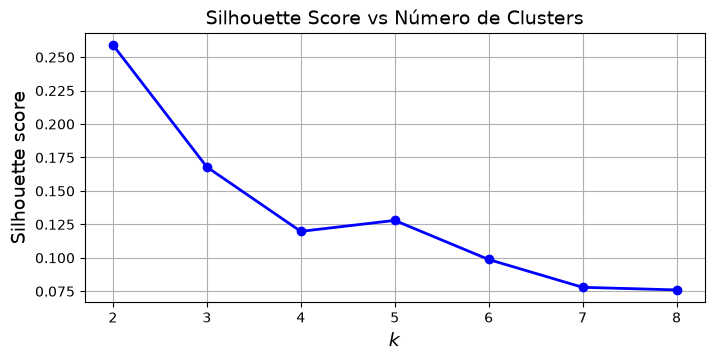

In [6]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# 1. Muestra representativa para cálculo rápido de distancias (ej. 3000 parches)
np.random.seed(42)
idx_sub = np.random.choice(len(X), 3000, replace=False)
X_sub = X[idx_sub]

# 2. Definir rango de k (evaluamos de k=1 hasta max_k=8)
max_k = 8
ks = list(range(2, max_k + 1))

# Entrenar un modelo KMeans para cada k de 1 hasta max_k
kmeans_per_k = [KMeans(n_clusters=k, init="k-means++", n_init=5, random_state=42).fit(X_sub) for k in range(1, max_k + 1)]

# Calcular silhouette_scores para k >= 2 (tal como en tu clase)
silhouette_scores = [silhouette_score(X_sub, model.labels_) for model in kmeans_per_k[1:]]

# 3. Graficar la curva de silueta
plt.figure(figsize=(8, 3.5))
plt.plot(ks, silhouette_scores, "bo-", linewidth=2)
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

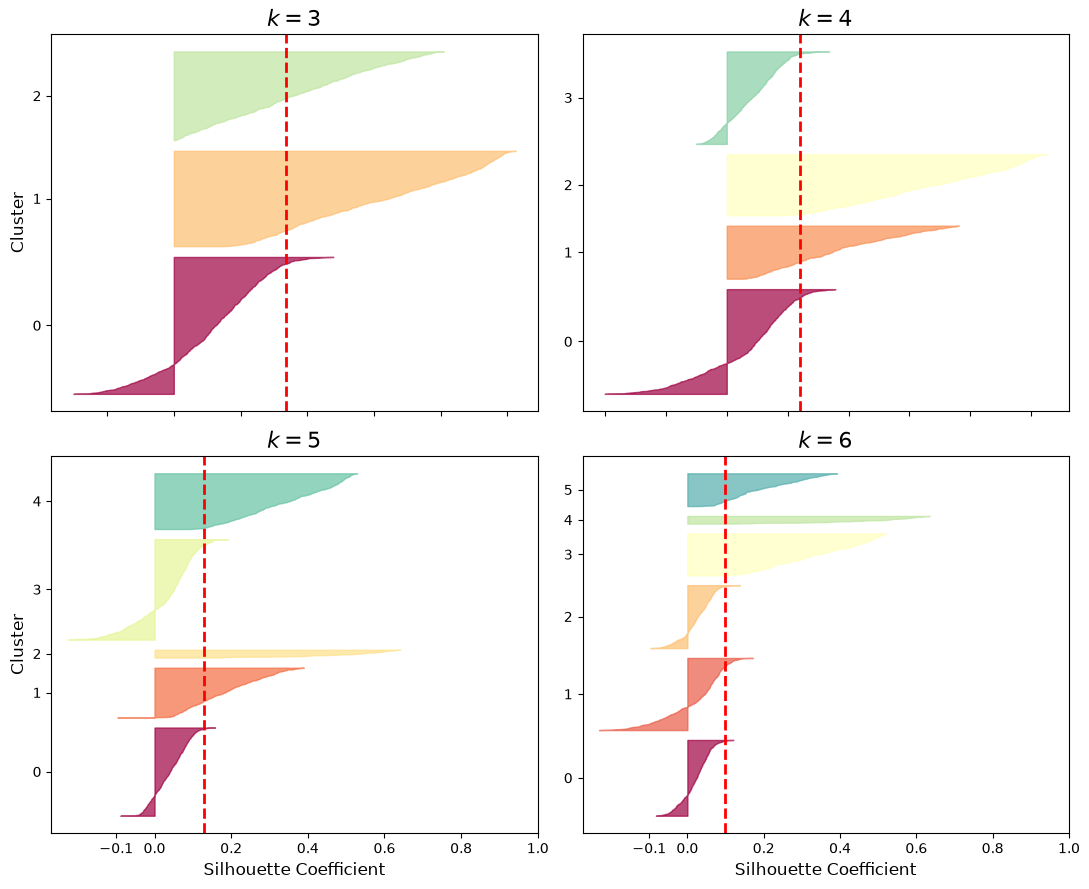

In [7]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

plt.figure(figsize=(11, 9))

valid_ks = [k for k in (3, 4, 5, 6) if k <= len(kmeans_per_k)]

for plot_idx, k in enumerate(valid_ks):
    plt.subplot(2, 2, plot_idx + 1)

    y_pred_k = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X_sub, y_pred_k)

    padding = len(X_sub) // 30
    pos = padding
    ticks = []
    
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred_k == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    
    if k in (3, 5):
        plt.ylabel("Cluster", fontsize=12)

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient", fontsize=12)
    else:
        plt.tick_params(labelbottom=False)

    # Línea vertical roja con el promedio del coeficiente de silueta
    if k - 2 < len(silhouette_scores):
        plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--", linewidth=2)
        
    plt.title(f"$k={k}$", fontsize=16)

plt.tight_layout()
plt.show()

## **Clasificador Multiclase y Métricas Finales. -**

Entrenando con Mini-batches en PyTorch...
Epoch  1/25 | Loss promedio: 1.6300
Epoch  5/25 | Loss promedio: 1.1313
Epoch 10/25 | Loss promedio: 1.0094
Epoch 15/25 | Loss promedio: 0.9609
Epoch 20/25 | Loss promedio: 0.8824
Epoch 25/25 | Loss promedio: 0.8255

¡Entrenamiento completado!

EXACTITUD (Accuracy) FINAL DEL MODELO: 66.96%

Reporte de Clasificación:
                  precision    recall  f1-score   support

      Vegetación       0.65      0.75      0.70       735
      Suelo/Paja       0.67      0.52      0.58       667
Basura/Plásticos       0.55      0.80      0.65       387
    Sombra/Barro       0.93      0.65      0.77       475

        accuracy                           0.67      2264
       macro avg       0.70      0.68      0.67      2264
    weighted avg       0.70      0.67      0.67      2264



<Figure size 700x600 with 0 Axes>

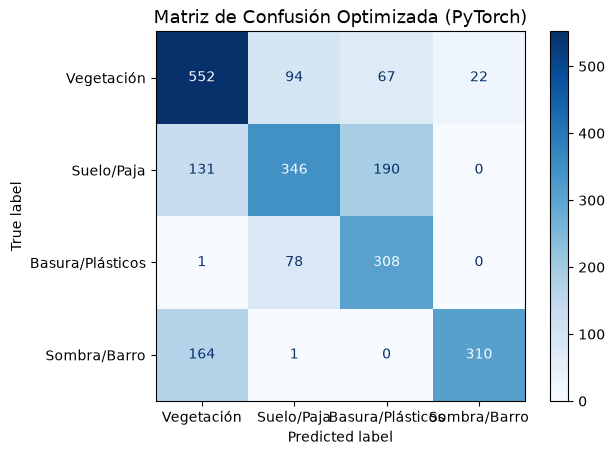

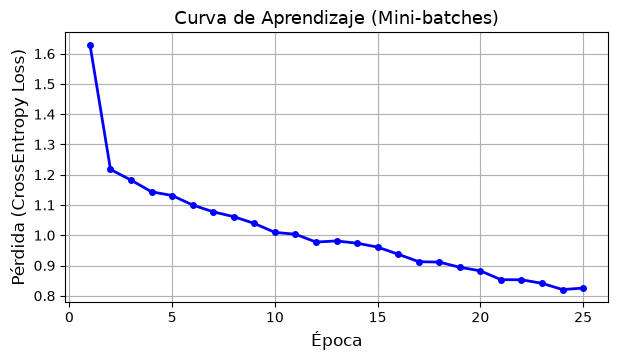

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Separación de datos: 80% Entrenamiento, 20% Prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y_pred, test_size=0.2, random_state=42, stratify=y_pred
)

device = torch.device("cpu")

X_t = torch.from_numpy(X_train).float().to(device)
Y_t = torch.from_numpy(y_train).long().to(device)

X_test_t = torch.from_numpy(X_test).float().to(device)
Y_test_t = torch.from_numpy(y_test).long().to(device)

# 2. Creación del DataLoader en mini-batches (128 muestras por lote)
batch_size = 128
train_dataset = TensorDataset(X_t, Y_t)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# 3. Definición de la Red Neuronal (ajustando dropout a 0.2 para facilitar convergencia)
D_in = 64 * 64 * 3   # 12,288
H = 128
D_out = 4

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(D_in, H),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(H, D_out)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

# 4. Bucle de Entrenamiento con Mini-batches
epochs = 25
historial_loss = []

print("Entrenando con Mini-batches en PyTorch...")
for e in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    
    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_logits = model(x_batch)
        loss = criterion(y_logits, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(y_batch)
        
    epoch_loss = running_loss / len(X_train)
    historial_loss.append(epoch_loss)
    
    if e % 5 == 0 or e == 1:
        print(f"Epoch {e:2d}/{epochs} | Loss promedio: {epoch_loss:.4f}")

print("\n¡Entrenamiento completado!")

# 5. Evaluación en el conjunto de prueba
model.eval()
with torch.no_grad():
    y_test_logits = model(X_test_t)
    y_pred_test = torch.argmax(y_test_logits, dim=1).cpu().numpy()

# 6. Métricas finales
nombres_clases = ["Vegetación", "Suelo/Paja", "Basura/Plásticos", "Sombra/Barro"]
acc = accuracy_score(y_test, y_pred_test)

print("\n" + "="*55)
print(f"EXACTITUD (Accuracy) FINAL DEL MODELO: {acc * 100:.2f}%")
print("="*55)

print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_test, target_names=nombres_clases))

# 7. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)

plt.figure(figsize=(7, 6))
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusión Optimizada (PyTorch)", fontsize=13)
plt.grid(False)
plt.show()

# 8. Gráfica de Pérdida
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, epochs + 1), historial_loss, "b-o", linewidth=2, markersize=4)
plt.xlabel("Época", fontsize=12)
plt.ylabel("Pérdida (CrossEntropy Loss)", fontsize=12)
plt.title("Curva de Aprendizaje (Mini-batches)", fontsize=13)
plt.grid(True)
plt.show()
